In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
image_size = 256
batch_size = 32
chanels = 3
epochs = 50

In [3]:
from pathlib import Path

# Resolve the dataset relative to this notebook so it works from any working directory.
DATA_DIR = Path.cwd() / "planttVillage"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR.resolve()}")

dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    shuffle=True,
    image_size=(256, 256),
    batch_size=32
)

Found 2152 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [5]:
len(dataset)

68

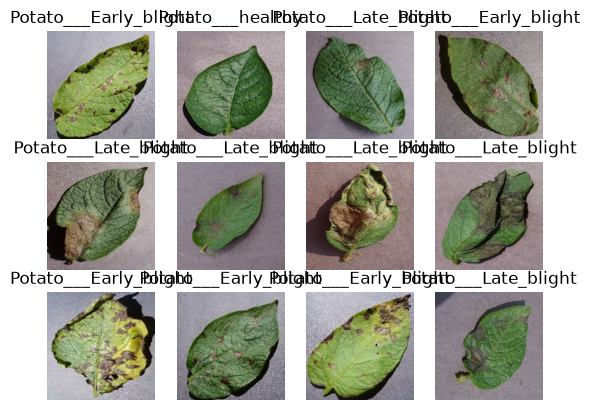

In [6]:
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

In [7]:
len(dataset)

68

In [8]:
train_size =0.8
len(dataset) * train_size

54.400000000000006

In [9]:
train_ds = dataset.take(int(len(dataset) * train_size))

In [12]:
test_ds = dataset.skip(int(len(dataset) * train_size))
len(train_ds)

54

In [13]:
val_ds = test_ds.take(6)
len(val_ds)

6

In [14]:
test_ds = test_ds.skip(6)
len(test_ds)

8

In [ ]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    
    return 